In [ ]:
from google.colab import drive, userdata
import os, sys
drive.mount('/content/drive')

TOKEN = userdata.get('GITHUB_TOKEN')
USER, REPO = "jeevithrao", "ML_AL_MC"
REPO_DIR = f"/content/{REPO}"
if not os.path.exists(REPO_DIR):
    !git clone https://{TOKEN}@github.com/{USER}/{REPO}.git {REPO_DIR}
%cd {REPO_DIR}
!git remote set-url origin https://{TOKEN}@github.com/{USER}/{REPO}.git
!git config user.name "jeevithrao"
!git config user.email "138958136+jeevithrao@users.noreply.github.com"
!git pull origin main
sys.path.append(f"{REPO_DIR}/src")
os.environ["PYTHONPATH"] = f"{REPO_DIR}/src"

Mounted at /content/drive
Cloning into '/content/ML_AL_MC'...
remote: Enumerating objects: 11, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (7/7), done.
remote: Total 11 (delta 2), reused 10 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (11/11), 396.31 KiB | 20.86 MiB/s, done.
Resolving deltas: 100% (2/2), done.
/content/ML_AL_MC
From https://github.com/jeevithrao/ML_AL_MC
 * branch            main       -> FETCH_HEAD
Already up to date.


In [ ]:
os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
ROOT = "/content/data/birdclef"

if not os.path.exists(f"{ROOT}/train_metadata.csv"):
    !pip install -q kaggle
    !mkdir -p /content/data
    !kaggle competitions download -c birdclef-2024 -p /content/data
    !unzip -q /content/data/birdclef-2024.zip -d {ROOT}
    !rm /content/data/birdclef-2024.zip
else:
    print("Dataset already present, skipping download.")

!pip install -q timm soundfile librosa
!ls {ROOT}

100% 21.8G/21.8G [04:17<00:00, 90.9MB/s]

eBird_Taxonomy_v2021.csv  test_soundscapes  train_metadata.csv
sample_submission.csv	  train_audio	    unlabeled_soundscapes


In [ ]:
!ls {ROOT}

eBird_Taxonomy_v2021.csv  test_soundscapes  train_metadata.csv
sample_submission.csv	  train_audio	    unlabeled_soundscapes


In [ ]:
%%writefile -a .gitignore
*.npz

Appending to .gitignore


In [ ]:
%%writefile src/audio_config.py
SR = 32000            # sample rate (Hz), native to the dataset
CHUNK_SEC = 5         # window length in seconds
N_MELS = 128          # mel bands (image height)
N_FFT = 1024          # FFT window
HOP = 512             # hop length -> 313 frames per 5 s
FMIN, FMAX = 50, 14000
TOP_DB = 80           # dynamic range kept below the loudest bin
MAX_READ_SEC = 60     # read at most this much audio per clip
N_CHUNKS = 3          # keep up to this many chunks per clip
MIN_TAIL_SEC = 1.0    # keep a leftover tail only if at least this long

Writing src/audio_config.py


In [ ]:
%%writefile src/preprocess.py
import numpy as np, soundfile as sf, librosa
from audio_config import *

def _load(path):
    with sf.SoundFile(path) as f:
        sr = f.samplerate
        y = f.read(frames=int(MAX_READ_SEC * sr), dtype="float32", always_2d=True)
    y = y.mean(axis=1)
    if sr != SR:
        y = librosa.resample(y, orig_sr=sr, target_sr=SR)
    return y

def _windows(y):
    L = SR * CHUNK_SEC
    n_full = len(y) // L
    wins = [y[i*L:(i+1)*L] for i in range(n_full)]
    starts = [i * CHUNK_SEC for i in range(n_full)]
    rem = y[n_full * L:]
    if n_full == 0 or len(rem) >= SR * MIN_TAIL_SEC:
        if len(rem) == 0:
            rem = np.zeros(L, dtype=np.float32)
        wins.append(np.resize(rem, L))        # repeat the audio to fill the window
        starts.append(n_full * CHUNK_SEC)
    return wins, starts

def clip_to_mels(path):
    y = _load(path)
    wins, starts = _windows(y)
    rms = np.array([np.sqrt(np.mean(w.astype(np.float64) ** 2)) for w in wins])
    k = min(N_CHUNKS, len(wins))
    keep = np.sort(np.argsort(rms)[::-1][:k])  # loudest k, back in time order
    mels = []
    for j in keep:
        m = librosa.feature.melspectrogram(
            y=wins[j], sr=SR, n_fft=N_FFT, hop_length=HOP,
            n_mels=N_MELS, fmin=FMIN, fmax=FMAX, power=2.0)
        mels.append(librosa.power_to_db(m, ref=np.max, top_db=TOP_DB).astype(np.float16))
    return np.stack(mels), np.array(starts)[keep], rms[keep].astype(np.float32)

Writing src/preprocess.py


shape: (3, 128, 313) float16 | value range: -80.0 0.0
chunk start times (s): [ 0 20 25] | rms: [0.0074 0.0096 0.0171]


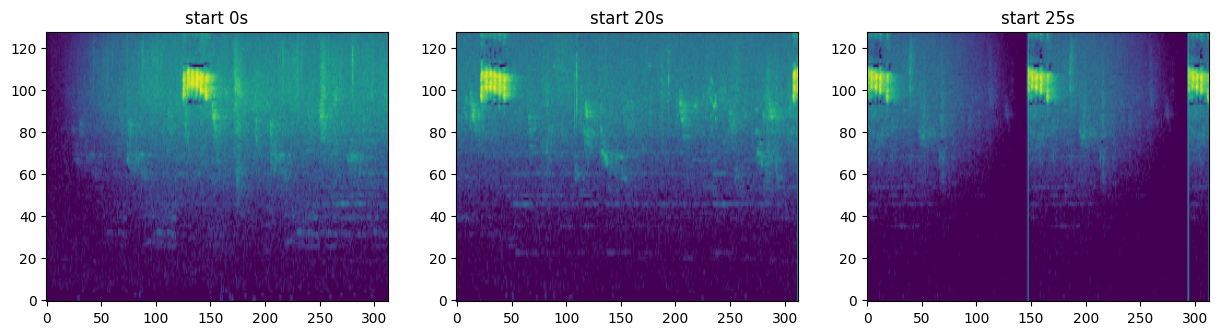

In [ ]:
import importlib, pandas as pd, numpy as np, matplotlib.pyplot as plt
import audio_config, preprocess
importlib.reload(audio_config); importlib.reload(preprocess)
from preprocess import clip_to_mels

meta = pd.read_csv(f"{ROOT}/train_metadata.csv")
fn = meta.filename.iloc[0]
mels, starts, rms = clip_to_mels(f"{ROOT}/train_audio/{fn}")
print("shape:", mels.shape, mels.dtype, "| value range:", mels.min(), mels.max())
print("chunk start times (s):", starts, "| rms:", rms.round(4))

fig, ax = plt.subplots(1, len(mels), figsize=(5 * len(mels), 3.5))
for a, m, s in zip(np.atleast_1d(ax), mels, starts):
    a.imshow(m.astype(np.float32), origin="lower", aspect="auto"); a.set_title(f"start {s}s")
plt.show()

In [ ]:
from joblib import Parallel, delayed
from tqdm.auto import tqdm
import time

OUT = "/content/data/mels"; os.makedirs(OUT, exist_ok=True)

def work(fn):
    out = f"{OUT}/{fn.replace('/', '__')}.npz"
    if os.path.exists(out):
        return fn, True
    try:
        m, s, r = clip_to_mels(f"{ROOT}/train_audio/{fn}")
        tmp = out + ".tmp.npz"
        np.savez(tmp, mel=m, start=s, rms=r)
        os.replace(tmp, out)          # atomic: a finished file appears all at once
        return fn, True
    except Exception as e:
        return fn, False

def run(files):
    gen = Parallel(n_jobs=-1, return_as="generator")(delayed(work)(f) for f in files)
    return list(tqdm(gen, total=len(files)))

print("CPU cores:", os.cpu_count())
test_files = meta.filename.sample(50, random_state=0).tolist()
t0 = time.time()
res = run(test_files)
dt = time.time() - t0
print(f"{dt:.1f}s for 50 clips -> estimated full run: {dt/50*len(meta)/60:.0f} min")
print("failed:", sum(not ok for _, ok in res))

CPU cores: 2


  0%|          | 0/50 [00:00<?, ?it/s]

10.8s for 50 clips -> estimated full run: 88 min
failed: 0


In [ ]:
t0 = time.time()
res = run(meta.filename.tolist())
bad = [f for f, ok in res if not ok]
print(f"done in {(time.time()-t0)/60:.1f} min | failed: {len(bad)}")
pd.Series(bad, name="filename").to_csv("results/failed_files.csv", index=False)

  0%|          | 0/24459 [00:00<?, ?it/s]

done in 24.7 min | failed: 0


In [17]:
import json
sub = pd.read_csv(f"{ROOT}/sample_submission.csv", nrows=1)
CLASSES = sub.columns[1:].tolist()
print("classes match primary labels:", set(CLASSES) == set(meta.primary_label), "| n =", len(CLASSES))

rng = np.random.RandomState(42)
assign = {}
for lab, g in meta.groupby("primary_label"):
    files = g.filename.values.copy()
    rng.shuffle(files)
    n = len(files)
    n_val = max(1, round(0.15 * n)); n_test = max(1, round(0.15 * n))
    for i, f in enumerate(files):
        assign[f] = "val" if i < n_val else "test" if i < n_val + n_test else "train"
meta["split"] = meta.filename.map(assign)

print(meta.split.value_counts())
print("species per split:", meta.groupby("split").primary_label.nunique().to_dict())
json.dump(CLASSES, open("results/classes.json", "w"))
meta[["filename", "primary_label", "secondary_labels", "rating", "split"]].to_csv("results/file_splits.csv", index=False)

classes match primary labels: True | n = 182
split
train    17125
val       3667
test      3667
Name: count, dtype: int64
species per split: {'test': 182, 'train': 182, 'val': 182}


In [18]:
rows = []
for fn in tqdm(meta.filename):
    p = f"{OUT}/{fn.replace('/', '__')}.npz"
    if not os.path.exists(p):
        continue
    z = np.load(p)
    st, rm = z["start"], z["rms"]
    for i in range(len(st)):
        rows.append((fn, i, int(st[i]), float(rm[i])))

idx = pd.DataFrame(rows, columns=["filename", "chunk", "start_sec", "rms"])
idx = idx.merge(meta[["filename", "primary_label", "secondary_labels", "rating", "split"]], on="filename")
idx.to_csv("results/chunk_index.csv", index=False)

print(idx.shape)
print(idx.split.value_counts())
print("species per split:", idx.groupby("split").primary_label.nunique().to_dict())
print("chunks per train species (min / median / max):",
      idx[idx.split == "train"].primary_label.value_counts().agg(["min", "median", "max"]).tolist())
print("chunks with near-zero loudness:", (idx.rms < 1e-4).sum())

  0%|          | 0/24459 [00:00<?, ?it/s]

(65644, 8)
split
train    45946
test      9855
val       9843
Name: count, dtype: int64
species per split: {'test': 182, 'train': 182, 'val': 182}
chunks per train species (min / median / max): [5.0, 111.5, 1040.0]
chunks with near-zero loudness: 14


In [19]:
!du -sh /content/data/mels
!df -h /content/drive | tail -1

5.0G	/content/data/mels
drive            15G   12M   15G   1% /content/drive


In [20]:
!tar -cf /content/drive/MyDrive/birdclef_project/mels.tar -C /content/data mels
!ls -lh /content/drive/MyDrive/birdclef_project/

total 5.0G
-rw------- 1 root root 5.0G Nov 10 06:59 mels.tar
-rw------- 1 root root 4.9M Nov  8 06:32 train_metadata.csv
